# Pronostico

Predecir la inflacion del mes que viene de cada rubro en cada region, y ver si un modelo le gana a lo mas simple, que es suponer que el mes que viene va a ser igual a este.

Codigo en `src/monitor/pronostico.py`.

- **Cuando se pronostica.** Cuando el INDEC publica el mayorista del mes anterior (desde 2018, entre el 14 y el 23 de cada mes; ver el notebook 04). Para ese momento se sabe: el IPC y el mayorista de T-1, la inflacion general, el REM de fines de T-1 y el dolar de los dias de T anteriores a esa publicacion. Todos los features salen de eso y nada mas.
- **Datos de afuera del INDEC.** Del BCRA: el dolar mayorista y la mediana del REM (lo que esperan los analistas). Sin eso, un tercio del error era un shock que pegaba a todos los rubros a la vez y ninguna variable del rubro lo podia ver.
- **Modelos.** Tres de referencia (naive = repetir el ultimo mes, promedio de 3 meses, mismo mes del anio anterior), una regresion lineal por serie (ARX) y un LightGBM global para las 120 series juntas (114 de rubros y el nivel general de cada region). El pronostico final es el promedio de LightGBM y ARX.
- **Validacion.** Origen movil: para cada uno de los ultimos 36 meses se entrena solo con lo anterior y se predice ese mes. Las decisiones (que variables, que modelo) las tome mirando solo nov-23 a oct-25. El ultimo anio quedo guardado como prueba final y se miro una sola vez.
- **Datos revisados.** El backtest usa los datos de hoy, no los que se tenian en su momento. En este caso da lo mismo: el INDEC nunca corrigio una variacion mensual (notebook 04). Igual cada pronostico nuevo queda en `data/resultados/registro_pronosticos.csv` sin pisarse, para medir el error real de aca en adelante.

In [1]:
import os

import lightgbm as lgb
import matplotlib.pyplot as plt
import pandas as pd

from monitor import analisis as a
from monitor import pronostico as p

a.estilo()
con = a.conectar()
nombres = a.nombres_rubros(con)
panel = p.datos(con)

pred = p.calibrar(p.backtest(panel, meses=48, procesos=os.cpu_count()))
pred = pred[pred.ajuste.notna() & (pred.fecha >= sorted(pred.fecha.unique())[-36])].copy()
meses = sorted(pred.fecha.unique())
pred["tramo"] = (pred.fecha >= meses[-12]).map({False: "desarrollo", True: "prueba final"})
pred["anio"] = pred.fecha.dt.year
# el nivel general se mira aparte, al final: es mucho mas suave y bajaria el error promedio
es_general = pred.par_id == p.NIVEL_GENERAL
general, pred = pred[es_general].copy(), pred[~es_general].copy()
print(
    f"{len(pred)} pronosticos de rubros y {len(general)} de nivel general, "
    f"de {meses[0]:%m-%Y} a {meses[-1]:%m-%Y}"
)

4104 pronosticos de rubros y 216 de nivel general, de 11-2023 a 10-2026


## 1. Quien gana

In [2]:
tabla = p.metricas(pred, p.escala_mase(panel, pred.fecha.min()))
tabla.round(3)

,mae_pp,rmse_pp,mase,vs_naive,cobertura_80_cruda,cobertura_80_calibrada,cobertura_90_calibrada
modelo,,,,,,,
naive,2.884,5.553,1.256,1.000,NaN,NaN,NaN
media3,3.125,5.672,1.441,1.083,NaN,NaN,NaN
estacional,5.822,9.360,2.892,2.019,NaN,NaN,NaN
arx,2.476,4.483,1.101,0.859,NaN,NaN,NaN
lgbm,2.317,4.469,1.027,0.804,NaN,NaN,NaN
combinado,2.240,4.171,0.979,0.777,0.666,0.8,0.902


- `mae_pp` es el error medio en puntos porcentuales de inflacion mensual. El combinado queda en 2.24 contra 2.88 del naive: un 22% menos.
- `vs_naive` es el error relativo al naive, debajo de 1 es mejor.
- El MASE da arriba de 1 para casi todos porque se escala con el error de la historia previa, que fue mas tranquila que el periodo de prueba (arranca justo antes de diciembre de 2023). Por eso miro `vs_naive`.
- El mismo mes del anio anterior es el peor: con una inflacion que cambia tanto de un anio a otro no sirve.

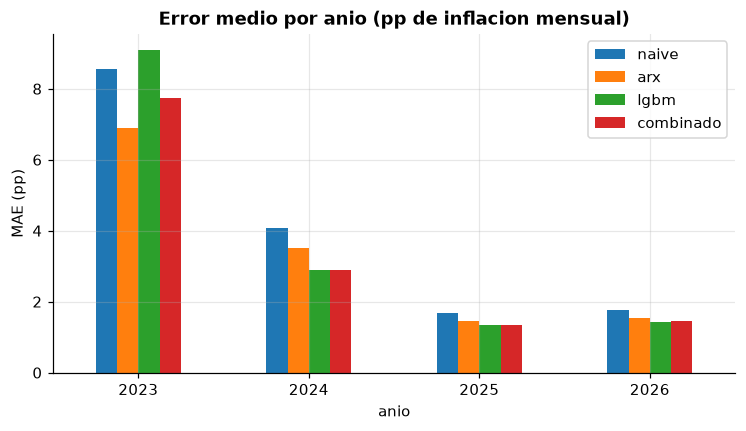

,naive,arx,lgbm,combinado
anio,,,,
2023,8.55,6.89,9.09,7.74
2024,4.07,3.52,2.90,2.89
2025,1.68,1.47,1.34,1.33
2026,1.78,1.55,1.44,1.45


In [3]:
modelos = ["naive", "arx", "lgbm", "combinado"]
por_anio = pred.groupby("anio").apply(
    lambda d: pd.Series({m: 100 * (d.y - d[m]).abs().mean() for m in modelos}), include_groups=False
)
ax = por_anio.plot.bar(figsize=(8, 4), rot=0)
ax.set_title("Error medio por anio (pp de inflacion mensual)")
ax.set_ylabel("MAE (pp)")
plt.show()
por_anio.round(2)

2023 son solo noviembre y diciembre, con la devaluacion de diciembre. Ahi se ve por que combinar: LightGBM erra 9.1 y el ARX 6.9. Un arbol no puede pronosticar mas alla de lo que vio al entrenar, y un salto del dolar como ese no lo habia visto nunca; la regresion lineal si extrapola. Desde 2024 LightGBM y el combinado andan parecido y los dos le ganan al naive por mas de un 15% todos los anios.

## 2. Que aporto el BCRA

Mismo LightGBM sin las tres variables del BCRA, para comparar.

In [4]:
con_y = panel[panel.y.notna()]
sin_bcra = [f for f in p.FEATURES if f not in p.FEATURES_BCRA]
partes = []
for mes in meses:
    tr, te = con_y[con_y.fecha < mes], con_y[con_y.fecha == mes]
    m = lgb.train(
        p.PARAMS, lgb.Dataset(tr[sin_bcra], tr.y, categorical_feature=p.CATEGORICAS), p.ARBOLES
    )
    partes.append(te[["par_id", "region", "fecha"]].assign(sin_bcra=m.predict(te[sin_bcra])))
pred = pred.merge(pd.concat(partes), on=["par_id", "region", "fecha"])

comparar = ["naive", "sin_bcra", "lgbm", "combinado"]
pred.groupby("tramo").apply(
    lambda d: pd.Series({m: 100 * (d.y - d[m]).abs().mean() for m in comparar}),
    include_groups=False,
).round(3)

,naive,sin_bcra,lgbm,combinado
tramo,,,,
desarrollo,3.465,3.014,2.775,2.652
prueba final,1.723,1.424,1.403,1.416


- **Desarrollo (nov-23 a oct-25):** con el BCRA el error baja de 3.01 a 2.78, y el combinado a 2.65. Es la etapa con saltos del dolar.
- **Prueba final (nov-25 a oct-26):** casi empatan (1.42 sin BCRA, 1.40 con). En un anio calmo el dolar casi no se mueve y no tiene nada para aportar.

O sea: el BCRA no mejora los meses tranquilos, pero tampoco los empeora, y paga cuando hay un shock. Para un monitor de precios en Argentina es un seguro que vale la pena. Lo dejo dicho asi porque la prueba final no muestra la mejora: la evidencia sale del tramo de desarrollo, que es donde tome las decisiones, asi que puede estar un poco inflada.

## 3. Es una mejora de verdad?

Test de Diebold-Mariano: compara los errores de dos modelos mes a mes. Promedio el error de todas las series de cada mes para no contar 114 veces el mismo shock.

In [5]:
pd.DataFrame(
    [
        p.diebold_mariano(pred, "combinado", b)
        for b in ["naive", "media3", "arx", "sin_bcra", "lgbm"]
    ]
).round(4)

,a,b,dif_mae_pp,estadistico,p_valor
0,combinado,naive,-0.6440,-3.6265,0.0009
1,combinado,media3,-0.8844,-2.9146,0.0062
2,combinado,arx,-0.2361,-2.1960,0.0348
3,combinado,sin_bcra,-0.2439,-1.9822,0.0554
4,combinado,lgbm,-0.0773,-1.0507,0.3006


Contra el naive, el promedio de 3 meses y el ARX, el combinado gana con p < 0.05. Contra el LightGBM sin BCRA queda justo en el limite (p = 0.055), y contra LightGBM con BCRA no hay diferencia significativa (p = 0.30): combinar no mejora el promedio, lo que hace es cubrir los meses de shock.

## 4. Intervalos

Ademas del numero, el modelo da dos bandas: una donde deberia caer el dato 8 de cada 10 meses (80%) y otra mas ancha para 9 de cada 10 (90%), como los graficos de abanico de los bancos centrales.

- Salen de los cuantiles 10 y 90 de LightGBM, corridos para que queden alrededor del pronostico combinado.
- Los cuantiles solos quedan cortos, asi que los calibro con conformal: cada mes ensancho la banda de cada rubro segun cuanto fallo ese rubro en los 12 meses anteriores. Por rubro y no uno para todos porque si no verduras cubria 67% y pan 88%.
- El ensanche se multiplica por 1 + 10 x lo que se movio el dolar en los primeros dias del mes. Con una ventana de 12 meses el conformal tarda en enterarse de un shock; el dolar avisa antes. En dic-2023 la banda del 80% paso de cubrir 36% a 50%, sin perder cobertura en el resto ni ensanchar los meses tranquilos. El 10 no esta ajustado: cualquier valor entre 3 y 20 da parecido.

In [6]:
cobertura = pred.groupby("anio").apply(
    lambda d: pd.Series(
        {
            "cruda": d.y.between(d.lgbm_q10, d.lgbm_q90).mean(),
            "banda_80": d.y.between(d.lgbm_inf, d.lgbm_sup).mean(),
            "banda_90": d.y.between(d.lgbm_inf_90, d.lgbm_sup_90).mean(),
            "ancho_80_pp": 100 * (d.lgbm_sup - d.lgbm_inf).mean(),
            "ancho_90_pp": 100 * (d.lgbm_sup_90 - d.lgbm_inf_90).mean(),
        }
    ),
    include_groups=False,
)
dic = pred.fecha == "2023-12-01"
for suf, nivel in [("", "80%"), ("_90", "90%")]:
    cubre = pred.y.between(pred["lgbm_inf" + suf], pred["lgbm_sup" + suf])
    rub = cubre.groupby(pred.par_id).mean()
    print(f"banda {nivel}: {cubre.mean():.1%} total, rubros {rub.min():.0%} a {rub.max():.0%}")
    print(f"           dic-2023 {cubre[dic].mean():.0%}")
cobertura.round(2)

banda 80%: 80.0% total, rubros 77% a 85%
           dic-2023 50%
banda 90%: 90.2% total, rubros 84% a 94%
           dic-2023 76%


,cruda,banda_80,banda_90,ancho_80_pp,ancho_90_pp
anio,,,,,
2023,0.24,0.46,0.62,12.38,20.42
2024,0.66,0.87,0.94,11.40,15.32
2025,0.72,0.80,0.92,5.17,7.74
2026,0.69,0.79,0.90,4.61,6.20


Las dos bandas cubren lo que prometen: 80% y 90% en total. En 2024 sobran un poco porque la calibracion arrastra la devaluacion; en 2025-2026 andan en su nivel. Diciembre de 2023 sigue siendo el peor mes (50% y 76%): con el dolar mejora, pero un salto asi no se termina de ver venir.

Con volatilidad estable el conformal da justo 80% (hay un test con datos simulados). Probe tambien conformal adaptativo (ACI), que corrige el nivel mes a mes, y en estos datos no mejoro nada.

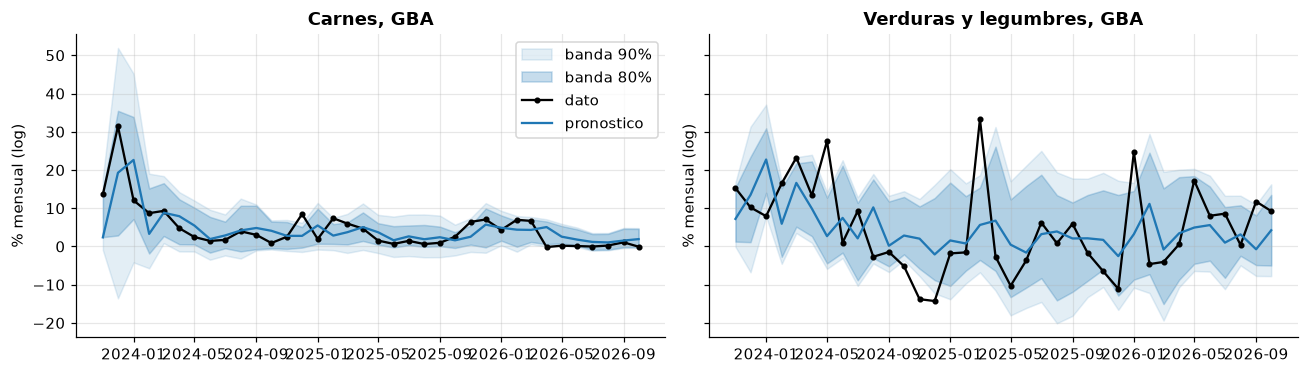

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
for ax, rubro in zip(axes, ["carnes", "verduras"], strict=True):
    s = pred[(pred.par_id == rubro) & (pred.region == "GBA")].set_index("fecha")
    ax.fill_between(
        s.index, 100 * s.lgbm_inf_90, 100 * s.lgbm_sup_90, color="C0", alpha=0.12, label="banda 90%"
    )
    ax.fill_between(
        s.index, 100 * s.lgbm_inf, 100 * s.lgbm_sup, color="C0", alpha=0.25, label="banda 80%"
    )
    ax.plot(s.index, 100 * s.y, "k.-", label="dato")
    ax.plot(s.index, 100 * s.combinado, label="pronostico")
    ax.set_title(f"{nombres[rubro]}, GBA")
    ax.set_ylabel("% mensual (log)")
axes[0].legend()
plt.tight_layout()
plt.show()

En carnes el intervalo se achica a medida que baja la inflacion y el dato casi siempre cae adentro. Verduras tiene su propio ancho, mucho mayor, pero igual los saltos mas grandes quedan afuera: son shocks de oferta (clima, cosecha) que no se ven en ningun dato del mes anterior.

## 5. Que mira el modelo

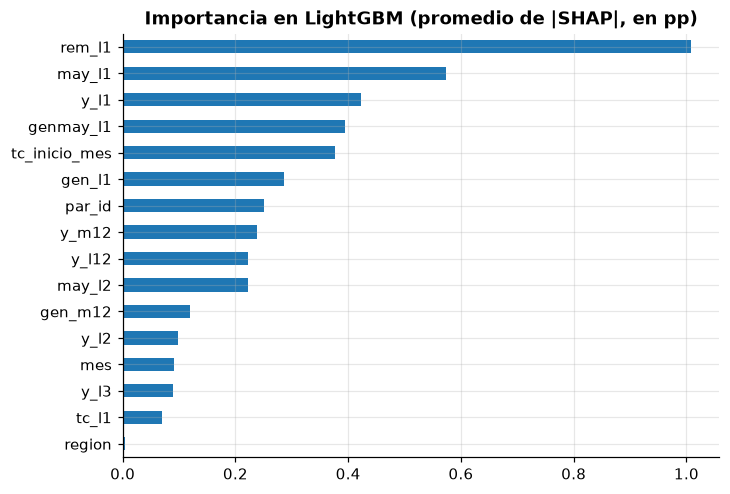

In [8]:
imp = p.importancia(panel)
ax = imp.plot.barh(figsize=(7, 5))
ax.set_title("Importancia en LightGBM (promedio de |SHAP|, en pp)")
plt.show()

Lo que mas pesa ahora es el **REM**. Lo que esperan los analistas probablemente resume cosas que el modelo no ve (tarifas anunciadas, acuerdos de precios), y ademas marca el nivel de inflacion de cada etapa. Despues viene el **mayorista del mes anterior**, el del rubro y el general, que encaja con el modelo de traslado: la suba mayorista llega a la gondola en el mismo mes o en el siguiente. El dolar de los primeros dias del mes aparece arriba de la inflacion general del mes anterior. La region casi no aporta, igual que en el traslado.

Esto es importancia para predecir, no causalidad.

## 6. El mes que viene

In [9]:
ultimos = pd.concat([pred, general])
ultimos = ultimos[ultimos.fecha >= meses[-12]]
proximo = p.pronosticar_proximo(panel, p.ajustes(ultimos, 0.2), p.ajustes(ultimos, 0.1))
print(f"pronostico para {proximo.fecha.iloc[0]:%m-%Y}, en % mensual")
(
    proximo[proximo.region == "GBA"]
    .set_index("par_id")
    .rename(index=nombres)[["inf_90", "inf", "pronostico", "sup", "sup_90"]]
    .sort_values("pronostico")
    .round(1)
)

pronostico para 11-2026, en % mensual


,inf_90,inf,pronostico,sup,sup_90
par_id,,,,,
Verduras y legumbres,-12.3,-9.6,0.0,11.3,14.7
Lacteos y huevos,-0.3,0.1,1.4,2.3,2.8
Prendas de vestir,-0.7,-0.4,1.4,2.6,2.8
Equipamiento del hogar,0.6,0.9,1.7,2.7,3.1
Aguas gaseosas y jugos,0.8,1.0,1.8,2.8,3.0
Calzado,-0.6,0.3,1.8,3.2,4.2
Azucar y golosinas,0.5,0.9,1.8,2.9,3.3
Bebidas alcoholicas,0.2,0.4,1.8,2.6,2.8
Aceites y grasas,-0.0,0.5,1.9,2.8,3.4


Se ve la estacionalidad del EDA: verduras para abajo en noviembre y frutas para arriba. Los intervalos mas anchos son los de verduras, frutas, combustibles, energia y carnes; los mas angostos, pan, medicamentos y equipamiento del hogar.

## 7. Nivel general de cada region

La web necesita un numero arriba de todo: cuanto va a dar la inflacion del mes que viene en cada region. Para eso el nivel general entra al modelo como una serie mas, con el IPIM general como su mayorista. Mismo modelo, mismas bandas, sin nada ajustado aparte.

In [10]:
modelos_ng = ["naive", "media3", "arx", "lgbm", "combinado"]
error_ng = general.groupby("anio").apply(
    lambda d: pd.Series({m: 100 * (d.y - d[m]).abs().mean() for m in modelos_ng}),
    include_groups=False,
)
error_ng.loc["36 meses"] = [100 * (general.y - general[m]).abs().mean() for m in modelos_ng]
print(p.diebold_mariano(general, "combinado", "naive"))
for suf, nivel in [("", "80%"), ("_90", "90%")]:
    print(
        f"banda {nivel}: cubre "
        f"{general.y.between(general['lgbm_inf' + suf], general['lgbm_sup' + suf]).mean():.1%}"
    )
error_ng.round(2)

{'a': 'combinado', 'b': 'naive', 'dif_mae_pp': np.float64(-0.3172073128679409), 'estadistico': np.float64(-1.4475000926431838), 'p_valor': np.float64(0.15665549343110352)}
banda 80%: cubre 77.8%
banda 90%: cubre 90.7%


,naive,media3,arx,lgbm,combinado
anio,,,,,
2023,7.64,6.72,5.28,8.51,6.89
2024,1.92,3.28,1.40,1.38,0.89
2025,0.49,0.55,0.59,0.54,0.51
2026,0.39,0.47,0.75,0.54,0.61
36 meses,1.34,1.78,1.16,1.26,1.02


- En los 36 meses el combinado erra 1.02 pp contra 1.34 del naive, pero el test no da significativo (p = 0.16): son 6 series muy parecidas entre si y casi toda la ventaja sale de 2023 y 2024.
- En 2025 empatan y en 2026 pierde (0.61 contra 0.39). Con la inflacion quieta el nivel general se mueve muy poco de un mes a otro, y repetir el ultimo dato es muy dificil de mejorar. Los rubros no tienen ese problema porque se mueven mucho mas.
- Las bandas cubren 78% y 91%.

Probe un par de arreglos (elegir entre el modelo y el naive segun quien vino mejor, corregir el sesgo), pero los compare contra la prueba final, que ya habia mirado. Elegir uno seria ajustar el modelo a esos 12 meses. Lo dejo como esta y la web muestra el pronostico junto a lo que daria repetir el ultimo dato, con el error de cada uno.

## Resumen

- El combinado (LightGBM + ARX) le gana a repetir el ultimo mes por un 22% en los 36 meses, y la diferencia es significativa.
- Sumar el dolar y el REM del BCRA mejora los periodos con shock y no cambia nada en los tranquilos.
- Las bandas cubren lo que tienen que cubrir (80% y 90%), parejo entre rubros, y se agrandan solas cuando salta el dolar.
- Lo que mas ayuda a predecir es el REM, despues el mayorista del mes anterior.
- En el nivel general de cada region le gana al naive en los anios de shock pero no en los tranquilos.

Limites: un solo mes de horizonte y una ventaja que se apoya en pocos meses de shock. Lo de usar datos ya revisados en el backtest no es problema: el INDEC nunca corrigio una variacion mensual (notebook 04).